In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report


In [7]:
#2.Load the dataset
# data =load_breast_cancer()
data= load_iris()
x=pd.DataFrame(data.data, columns=data.feature_names)
y=pd.Series(data.target) #0=malignant, 1= benign
x

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [8]:
print(f"Shape of data: {x.shape}")
print(f"Classes: {data.target_names}")
print(f"Count of each class:\n{y.value_counts()}")

Shape of data: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
Count of each class:
0    50
1    50
2    50
Name: count, dtype: int64


In [9]:
x.iloc[0:,0]

,sepal length (cm)
0,5.1
1,4.9
2,4.7
3,4.6
4,5.0
...,...
145,6.7
146,6.3
147,6.5
148,6.2


Text(0, 0.5, 'sepal width (cm)')

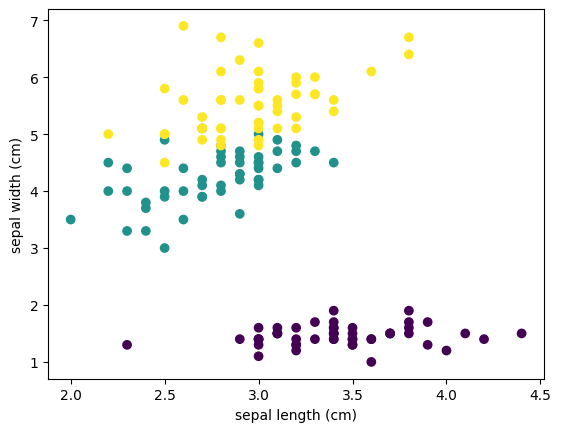

In [10]:
#visualize two features
plt.scatter(x.iloc[:,1],x.iloc[:,2],c=y)

plt.xlabel(data.feature_names[0])
plt.ylabel(data.feature_names[1])


In [11]:
# 3. Split into training and testind sets(80% train, 20% test)
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.2, random_state=42, stratify=y
)

In [12]:
# 4. feature scaling

scaler = StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)


In [20]:
# 5. Create amd train SVM model
model = SVC(kernel='rbf')
model.fit(x_train,y_train)

SVC()

In [21]:
# 6. Predict test data
y_pred = model.predict(x_test)

In [22]:
# 7. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy* 100:.2f}%")

Accuracy: 96.67%


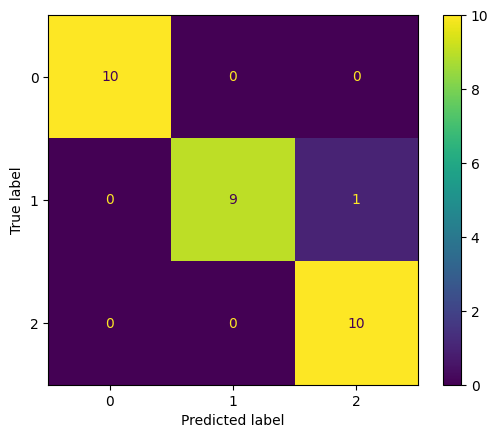

In [23]:
#step 8. Display common matrix

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot()

In [24]:
#9. Display calssification report
print("Classifictaion report")

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

Classifictaion report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

